# T-RAG · Notebook 6 — Combine the runs (CPU, ~5 minutes)

## About this notebook

**What it does :** This short notebook collects the results of Notebook 5 and the second set of sentiment labels from Notebook 4J, and makes the final tables and figures for the report.

For every version (B0 to B6) it gives:
* overall accuracy, with a 95% bootstrap confidence interval;
* accuracy per question type;
* McNemar tests on the same questions. For example, B6 is right where standard RAG is wrong on 141 questions, and the reverse happens on 14.

It also applies the **dual answer key**. Each sentiment question's correct answer is recomputed from the LLM judge's labels instead of FinBERT's, and every version is scored again. On the 98 sentiment questions where the judge gives a clear answer, the two keys agree 70% of the time. B6 scores 96% by the FinBERT key and 66% by the judge key, against 42% and 37% for standard RAG.

It also re-runs the NLI check of the explanations in full precision. The scores stay low, so we report this as a limitation. The notebook can merge runs of several models; our results come from one run (Qwen2.5-7B-Instruct).

**Needs :** the outputs of Notebooks 4, 4J and 5. GPU optional, about 5 minutes. Internet on.

**Produces :** `trag_final/` with the accuracy, category, McNemar, dual-key and faithfulness tables, figures and `summary_final.json`.

In [1]:
from pathlib import Path
import re, json, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import binomtest
warnings.filterwarnings("ignore")
pd.set_option("display.width", 180, "display.max_columns", 40)
END = "2023-12-31"
MIN_N = {"news": 20, "social": 10}; QUARTER_MIN_N = {"news": 60, "social": 30}
POS_T, NEG_T, MIX_T = 0.25, -0.25, 0.08
OUT = Path("/kaggle/working/trag_final") if Path("/kaggle/working").exists() else Path("trag_final")
(OUT / "figures").mkdir(parents=True, exist_ok=True)
SUMMARY = {}

TICKERS = ["TSLA", "AAPL", "MSFT", "NVDA", "AMZN", "META", "GOOGL", "NFLX", "AMD", "INTC"]
COMPANY = {"TSLA": "Tesla", "AAPL": "Apple", "MSFT": "Microsoft", "NVDA": "Nvidia", "AMZN": "Amazon",
           "META": "Meta", "GOOGL": "Alphabet", "NFLX": "Netflix", "AMD": "AMD", "INTC": "Intel", "ALL": "the market"}

In [2]:
def one(pattern, what):
    hits = sorted(glob.glob(f"/kaggle/input/**/{pattern}", recursive=True)) + sorted(glob.glob(pattern))
    if not hits: raise FileNotFoundError(f"{pattern} not found — attach {what}.")
    return hits[0]
chunks = pd.read_parquet(one("trag_index_v2/chunks_v2.parquet", "Notebook 4's output"))
coverage = pd.read_csv(one("trag_index_v2/coverage_v2.csv", "Notebook 4's output"))
prices = pd.read_parquet(one("trag_index_v2/prices.parquet", "Notebook 4's output"))
jp = sorted(glob.glob("/kaggle/input/**/trag_judge/llm_labels.parquet", recursive=True)) + sorted(glob.glob("trag_judge/llm_labels.parquet"))
judge = pd.read_parquet(jp[0]) if jp else None
if judge is None: print("⚠️ Notebook 4J's output not attached — the dual answer key will be skipped.")

RUNS = {}
for f in sorted(glob.glob("/kaggle/input/**/trag_eval_v2_*/answers_scored.parquet", recursive=True)) + sorted(glob.glob("trag_eval_v2_*/answers_scored.parquet")):
    d = Path(f).parent; name = d.name.replace("trag_eval_v2_", "")
    if name in RUNS: continue
    q = pd.read_parquet(d / "questions_v2.parquet"); a = pd.read_parquet(f)
    s = json.loads((d / "summary.json").read_text()) if (d / "summary.json").exists() else {}
    RUNS[name] = {"q": q, "a": a, "summary": s, "dir": d}
    print(f"run {name}: {s.get('llm', '?')} | {len(q)} questions | versions {sorted(a.version.unique())}")
assert RUNS, "attach at least one Notebook 5 output (trag_eval_v2_*)"

chunks["day0"] = pd.to_datetime(chunks.day0)
TICK = chunks.ticker.astype(str).values
SRC = chunks.source.astype(str).values
AV = pd.to_datetime(chunks.available_at, utc=True).values.astype("datetime64[ns]").astype(np.int64)   # UTC ns
DAY0 = chunks.day0.values.astype("datetime64[ns]")
POS = (chunks.label == "positive").values
NEG = (chunks.label == "negative").values
DOC_ID = chunks.doc_id.astype(str).values
DOC_IX = {d: i for i, d in enumerate(DOC_ID)}
PER_M = chunks.day0.dt.to_period("M")
PER_Q = chunks.day0.dt.to_period("Q")
DAY_NS = 86_400 * 10**9
coverage["coverage_start"] = pd.to_datetime(coverage.coverage_start)
coverage["coverage_end"] = pd.to_datetime(coverage.coverage_end)
COV = {(r.ticker, r.source): (r.coverage_start, r.coverage_end) for r in coverage.itertuples()}

J_HAS = J_POS = J_NEG = None
if judge is not None:
    jl = pd.DataFrame({"doc_id": DOC_ID}).merge(judge[["doc_id", "judge_label"]].drop_duplicates("doc_id"), on="doc_id", how="left")
    J_HAS = jl.judge_label.notna().values
    J_POS = (jl.judge_label == "positive").values
    J_NEG = (jl.judge_label == "negative").values
    print(f"LLM-judge labels available for {J_HAS.mean():.1%} of documents "
          f"(news {J_HAS[SRC == 'news'].mean():.1%}, social {J_HAS[SRC == 'social'].mean() if (SRC == 'social').any() else 0:.1%})")

prices["date"] = pd.to_datetime(prices.date)
RET = prices.pivot_table(index="date", columns="ticker", values="ret").sort_index()
ARW = prices.pivot_table(index="date", columns="ticker", values="ar").sort_index()
ZW = prices.pivot_table(index="date", columns="ticker", values="z").sort_index()

def ts(x): return pd.Timestamp(str(x)) if isinstance(x, np.str_) else pd.Timestamp(x)
def day_start(d): return ts(d).tz_localize("America/New_York").value
def cutoff(d): return (ts(d).tz_localize("America/New_York") + pd.Timedelta(days=1) - pd.Timedelta(seconds=1)).value

def time_mask(t, start=None, end=None, as_of=None, srcs=("news",)):
    m = (TICK == t) & np.isin(SRC, list(srcs))
    if start is not None: m &= AV >= day_start(start)
    if end is not None:   m &= AV <= cutoff(end)
    if as_of is not None: m &= AV <= cutoff(as_of)
    return m

def lab_arrays(lab):
    if lab == "finbert": return POS, NEG, None
    if J_HAS is None: raise ValueError("no judge labels loaded")
    return J_POS, J_NEG, J_HAS

def tone_of(m, lab="finbert"):
    P, N, H = lab_arrays(lab)
    if H is not None: m = m & H
    pos, neg = int(P[m].sum()), int(N[m].sum())
    return (pos - neg) / (pos + neg + 1), int(m.sum())

def tone_label(x):
    if x >= POS_T: return "positive"
    if x <= NEG_T: return "negative"
    if abs(x) <= MIX_T: return "mixed"
    return None

_tables = {}
def period_table(t, src, freq="M", lab="finbert"):
    key = (t, src, freq, lab)
    if key not in _tables:
        P, N, H = lab_arrays(lab)
        m = (TICK == t) & (SRC == src)
        if H is not None: m &= H
        per = (PER_M if freq == "M" else PER_Q)[m].values
        g = pd.DataFrame({"per": per, "pos": P[m], "neg": N[m]}).groupby("per").agg(
            n=("pos", "size"), pos=("pos", "sum"), neg=("neg", "sum")).reset_index()
        g["tone"] = (g.pos - g.neg) / (g.pos + g.neg + 1)
        g["start"] = g.per.dt.start_time; g["end"] = g.per.dt.end_time.dt.normalize()
        cs, ce = COV.get((t, src), (pd.Timestamp("2100-01-01"), pd.Timestamp("1900-01-01")))
        need = (MIN_N if freq == "M" else QUARTER_MIN_N)[src]
        g["ok"] = (g.n >= need) & (g.start >= cs) & (g.start <= ce) & (g.end <= ts(END))
        _tables[key] = g.sort_values("per").reset_index(drop=True)
    return _tables[key]

def excess_return(t, s, e, as_of=None):
    e2 = min(ts(e), ts(as_of)) if as_of is not None else ts(e)
    r = RET.loc[(RET.index >= ts(s)) & (RET.index <= e2)]
    if len(r) < 2 or t not in r or "QQQ" not in r: return None
    st = float((1 + r[t].fillna(0)).prod() - 1); mk = float((1 + r["QQQ"].fillna(0)).prod() - 1)
    return st, mk, st - mk, len(r)

def truth_from_spec(spec, lab="finbert"):
    """The answer key of a question, recomputed from a given set of labels. None = no clear answer."""
    if isinstance(spec, str): spec = json.loads(spec)
    k = spec["kind"]
    if k == "fixed": return spec["truth"]
    t, src = spec["t"], spec.get("src", "news")
    if k == "month_label":
        g = period_table(t, src, "M", lab); r = g[(g.per.astype(str) == spec["per"]) & g.ok]
        return tone_label(r.tone.iloc[0]) if len(r) else None
    if k == "window_label":
        x, n = tone_of(time_mask(t, spec["start"], spec["end"], srcs=[src]), lab)
        return tone_label(x) if n >= spec["min_n"] else None
    if k == "trend":
        g = period_table(t, src, "M", lab)
        ok = g[g.ok & (g.start >= ts(spec["start"])) & (g.end <= ts(spec["end"]))]
        if len(ok) < 4: return None
        d = ok.tone.iloc[-2:].mean() - ok.tone.iloc[:2].mean()
        return None if abs(d) < 0.3 else ("improved" if d > 0 else "worsened")
    if k == "extreme":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone", ascending=(spec["which"] == "most negative"))
        return None if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05 else srt.per.iloc[0].strftime("%Y-%m")
    if k == "quarter_compare":
        g = period_table(t, src, "Q", lab)
        a = g[(g.per.astype(str) == spec["pa"]) & g.ok]; b = g[(g.per.astype(str) == spec["pb"]) & g.ok]
        if not len(a) or not len(b) or abs(a.tone.iloc[0] - b.tone.iloc[0]) < 0.25: return None
        return spec["la"] if a.tone.iloc[0] > b.tone.iloc[0] else spec["lb"]
    if k == "before_after":
        d = ts(spec["d"])
        xb, nb = tone_of(time_mask(t, d - pd.Timedelta(days=28), d - pd.Timedelta(days=1), srcs=[src]), lab)
        xa, na = tone_of(time_mask(t, d, d + pd.Timedelta(days=27), srcs=[src]), lab)
        if min(nb, na) < 15 or abs(xa - xb) < 0.2: return None
        return "after" if xa > xb else "before"
    if k == "m1":
        g = period_table(t, src, "M", lab); m = g[g.ok & (g.per.dt.year == spec["year"])]
        if len(m) < 9: return None
        srt = m.sort_values("tone")
        if abs(srt.tone.iloc[0] - srt.tone.iloc[1]) < 0.05: return None
        r = srt.iloc[0]; x = excess_return(t, r.start, r.end)
        if x is None or abs(x[2]) < 0.03: return None
        return "outperformed" if x[2] > 0 else "underperformed"
    raise ValueError(k)

run qwen7b: Qwen/Qwen2.5-7B-Instruct | 317 questions | versions ['B0', 'B2', 'B3', 'B4', 'B5', 'B5r', 'B6', 'B6p']
LLM-judge labels available for 99.5% of documents (news 100.0%, social 100.0%)


## Step 1 — One question set across runs, and the dual answer key

In [3]:
names = list(RUNS)
base_q = RUNS[names[0]]["q"]
for n in names[1:]:
    same = set(RUNS[n]["q"].question) == set(base_q.question)
    print(f"{n}: same questions as {names[0]}: {same}")
    if not same:
        common = set(RUNS[n]["q"].question) & set(base_q.question)
        print(f"   → comparing on the {len(common)} questions they share")
QS = base_q.set_index("qid")

def is_correct(atype, pred, truth):
    if truth is None or (isinstance(truth, float) and np.isnan(truth)): return np.nan
    if truth == "insufficient data" or pred == "insufficient data": return pred == truth
    if atype == "date":
        try: return abs((ts(pred) - ts(truth)).days) <= 3
        except Exception: return False
    if atype == "number":
        try: return abs(float(pred) - float(truth)) / float(truth) <= 0.015
        except Exception: return False
    return pred == truth

JT = {}
if J_HAS is not None:
    for q in base_q.itertuples():
        if json.loads(q.spec)["kind"] != "fixed":
            JT[q.question] = truth_from_spec(q.spec, "judge")
    clear = {k: v for k, v in JT.items() if v is not None}
    fin = base_q.set_index("question").truth
    agree = np.mean([fin[k] == v for k, v in clear.items()]) if clear else np.nan
    print(f"Sentiment questions: {len(JT)} | judge key clear for {len(clear)} | keys agree on {agree:.1%} of those")
    SUMMARY["dual_key_overview"] = {"sentiment_questions": len(JT), "judge_clear": len(clear), "agreement": round(float(agree), 3)}

ALL = []
for n, R in RUNS.items():
    a = R["a"].merge(R["q"][["qid", "question", "answer_type"]], on="qid", how="left")
    a["run"] = n
    a["truth_judge2"] = a.question.map(JT) if JT else None
    a["correct_judge2"] = np.array([float(is_correct(t_, p_, j_)) if j_ is not None else np.nan
                                    for t_, p_, j_ in zip(a.answer_type, a.pred, a.truth_judge2)], dtype=float) if JT else np.nan
    ALL.append(a)
ALL = pd.concat(ALL, ignore_index=True)
ALL.to_parquet(OUT / "all_answers.parquet", index=False)

Sentiment questions: 153 | judge key clear for 98 | keys agree on 70.4% of those


## Step 2 — Accuracy of every model × version

In [4]:
ORDER = ["B0", "B2", "B3", "B4", "B5r", "B5", "B6p", "B6"]
def boot_ci(x, B=2000, seed=0):
    x = np.asarray(x, float); r = np.random.default_rng(seed)
    m = np.array([x[r.integers(0, len(x), len(x))].mean() for _ in range(B)])
    return np.percentile(m, 2.5), np.percentile(m, 97.5)
rows = []
for (n, v), g in ALL.groupby(["run", "version"]):
    lo, hi = boot_ci(g.correct.astype(float))
    rows.append({"run": n, "version": v, "n": len(g), "accuracy": g.correct.mean(), "ci_low": lo, "ci_high": hi,
                 "no_guard": g.correct_raw.mean(), "false_abstention": g[g.truth != "insufficient data"].abstained.mean(),
                 "citation_validity": g.cite_valid.mean()})
overall = pd.DataFrame(rows)
overall["v_order"] = overall.version.map({v: i for i, v in enumerate(ORDER)})
overall = overall.sort_values(["run", "v_order"]).drop(columns="v_order").round(3)
print(overall.to_string(index=False)); overall.to_csv(OUT / "overall_by_model.csv", index=False)
SUMMARY["overall"] = overall.to_dict("records")

CATS = ["point-in-time", "latest", "trend", "comparison", "event impact", "policy", "prices", "reported figures", "multi-hop", "unanswerable"]
bycat = ALL.pivot_table(index=["run", "version"], columns="category", values="correct", aggfunc="mean")
bycat = bycat.reindex(columns=[c for c in CATS if c in bycat.columns]).round(3)
print("\n", bycat.to_string()); bycat.to_csv(OUT / "category_by_model.csv")
SUMMARY["by_category"] = {f"{k[0]}/{k[1]}": v for k, v in bycat.to_dict("index").items()}

   run version   n  accuracy  ci_low  ci_high  no_guard  false_abstention  citation_validity
qwen7b      B0 317     0.183   0.142    0.227     0.183             0.620                NaN
qwen7b      B2 317     0.470   0.416    0.524     0.470             0.051              0.936
qwen7b      B3 317     0.580   0.527    0.634     0.580             0.071              0.941
qwen7b      B4 317     0.603   0.549    0.656     0.603             0.067              0.923
qwen7b     B5r 317     0.599   0.546    0.653     0.599             0.061              0.898
qwen7b      B5 317     0.754   0.707    0.801     0.751             0.034              0.866
qwen7b     B6p 317     0.864   0.823    0.902     0.864             0.020              0.850
qwen7b      B6 317     0.871   0.833    0.905     0.871             0.027              0.801

 category        point-in-time  latest  trend  comparison  event impact  policy  prices  reported figures  multi-hop  unanswerable
run    version                 

In [5]:
def mcnemar(x, y):
    b_only, a_only = int((~x & y).sum()), int((x & ~y).sum())
    p = binomtest(b_only, b_only + a_only, 0.5).pvalue if (b_only + a_only) else 1.0
    return b_only, a_only, round(p, 4)
rows = []
for n in RUNS:
    w = ALL[ALL.run == n].pivot(index="question", columns="version", values="correct").astype(bool)
    for a_, b_ in [("B2", "B6"), ("B4", "B6"), ("B5", "B6"), ("B0", "B2"), ("B2", "B5")]:
        if a_ in w and b_ in w:
            bo, ao, p = mcnemar(w[a_], w[b_])
            rows.append({"run": n, "comparison": f"{b_} vs {a_}", "newer right / older wrong": bo, "older right / newer wrong": ao, "p_value": p})
if len(RUNS) > 1:
    for v in ["B0", "B2", "B4", "B5", "B6"]:
        w = ALL[ALL.version == v].pivot(index="question", columns="run", values="correct").dropna().astype(bool)
        cols = list(w.columns)
        for i in range(len(cols)):
            for j in range(i + 1, len(cols)):
                bo, ao, p = mcnemar(w[cols[i]], w[cols[j]])
                rows.append({"run": f"{cols[j]} vs {cols[i]}", "comparison": v, "newer right / older wrong": bo, "older right / newer wrong": ao, "p_value": p})
mc = pd.DataFrame(rows); print(mc.to_string(index=False)); mc.to_csv(OUT / "mcnemar_all.csv", index=False)
SUMMARY["mcnemar"] = mc.to_dict("records")

   run comparison  newer right / older wrong  older right / newer wrong  p_value
qwen7b   B6 vs B2                        141                         14      0.0
qwen7b   B6 vs B4                         96                         11      0.0
qwen7b   B6 vs B5                         51                         14      0.0
qwen7b   B2 vs B0                        106                         15      0.0
qwen7b   B5 vs B2                        109                         19      0.0


## Step 3 — The dual answer key (FinBERT vs LLM judge)

In [6]:
if JT:
    s = ALL[ALL.correct_judge2.notna()]
    dual = s.groupby(["run", "version"]).agg(n=("correct", "size"), finbert_key=("correct", "mean"), judge_key=("correct_judge2", "mean")).reset_index()
    dual["v_order"] = dual.version.map({v: i for i, v in enumerate(ORDER)})
    dual = dual.sort_values(["run", "v_order"]).drop(columns="v_order").round(3)
    print("Accuracy on sentiment questions where the judge's key is clear:\n", dual.to_string(index=False))
    dual.to_csv(OUT / "dual_key_by_model.csv", index=False)
    SUMMARY["dual_key"] = dual.to_dict("records")

Accuracy on sentiment questions where the judge's key is clear:
    run version  n  finbert_key  judge_key
qwen7b      B0 98        0.122      0.133
qwen7b      B2 98        0.418      0.367
qwen7b      B3 98        0.551      0.439
qwen7b      B4 98        0.592      0.520
qwen7b     B5r 98        0.582      0.490
qwen7b      B5 98        0.745      0.673
qwen7b     B6p 98        0.939      0.663
qwen7b      B6 98        0.959      0.663


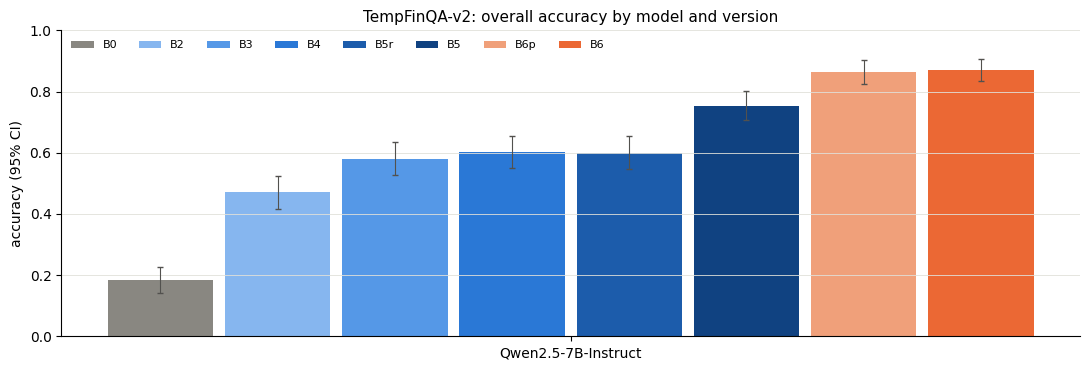

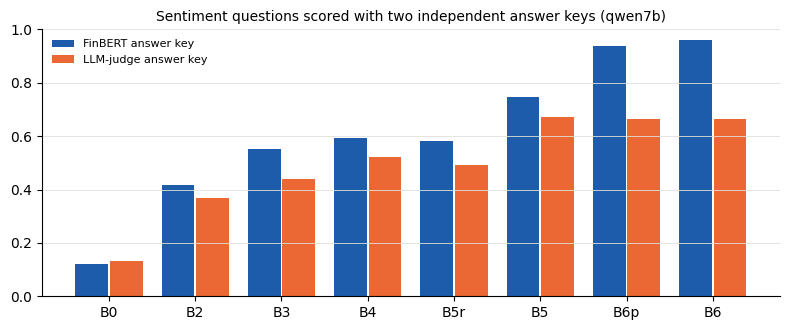

In [7]:
VCOL = {"B0": "#898781", "B2": "#86b6ef", "B3": "#5598e7", "B4": "#2a78d6", "B5r": "#1c5cab", "B5": "#104281", "B6p": "#f0a07a", "B6": "#eb6834"}
runs = list(RUNS); vs = [v for v in ORDER if v in overall.version.unique()]
fig, ax = plt.subplots(figsize=(11, 3.8)); w = 0.8 / len(vs)
for k, v in enumerate(vs):
    d = overall[overall.version == v].set_index("run").reindex(runs)
    x = np.arange(len(runs)) + k * w
    ax.bar(x, d.accuracy, w * 0.9, color=VCOL[v], label=v)
    ax.errorbar(x, d.accuracy, yerr=[d.accuracy - d.ci_low, d.ci_high - d.accuracy], fmt="none", ecolor="#52514e", lw=.8, capsize=2)
ax.set_xticks(np.arange(len(runs)) + w * (len(vs) - 1) / 2)
ax.set_xticklabels([RUNS[r]["summary"].get("llm", r).split("/")[-1] for r in runs])
ax.set_ylim(0, 1); ax.set_ylabel("accuracy (95% CI)"); ax.legend(ncol=len(vs), fontsize=8, frameon=False, loc="upper left")
ax.grid(axis="y", color="#e1e0d9", lw=.6); [ax.spines[s_].set_visible(False) for s_ in ("top", "right")]
ax.set_title("TempFinQA-v2: overall accuracy by model and version", fontsize=11)
plt.tight_layout(); plt.savefig(OUT / "figures" / "overall_by_model.png", dpi=170); plt.show()

if JT:
    d = dual[dual.run == runs[0]].set_index("version").reindex(vs).dropna(how="all")
    fig, ax = plt.subplots(figsize=(8, 3.4)); x = np.arange(len(d))
    ax.bar(x - 0.2, d.finbert_key, 0.38, color="#1c5cab", label="FinBERT answer key")
    ax.bar(x + 0.2, d.judge_key, 0.38, color="#eb6834", label="LLM-judge answer key")
    ax.set_xticks(x); ax.set_xticklabels(d.index); ax.set_ylim(0, 1); ax.legend(fontsize=8, frameon=False)
    ax.grid(axis="y", color="#e1e0d9", lw=.6); [ax.spines[s_].set_visible(False) for s_ in ("top", "right")]
    ax.set_title(f"Sentiment questions scored with two independent answer keys ({runs[0]})", fontsize=10)
    plt.tight_layout(); plt.savefig(OUT / "figures" / "dual_key.png", dpi=170); plt.show()

## Step 5 — Are the explanations grounded in the documents they cite? (NLI, recomputed for every run)

Notebook 5's own check gave implausibly low scores: the NLI model ran in half precision, which DeBERTa-v3 is known not to tolerate, and long tool text pushed the cited documents out of its 512-token window. Here every run is re-checked the same way, in full precision. For each explanation that cites at least one real document, the premise is **only the cited documents**, and the hypothesis is the explanation. The same is done for every claim in the showcase reports, with the report's event lines added to the premise.

This is strict for B5/B6: an explanation that quotes a tool number ("the timeline shows −0.46 in December") is not in any document, so it can count as unsupported even when it is correct.

In [9]:
def parse_json(txt):
    txt = txt or ""
    s, e = txt.find("{"), txt.rfind("}")
    if s >= 0 and e > s:
        frag = txt[s:e + 1]
        for cand in (frag, frag.replace("'", '"'), re.sub(r",\s*([}\]])", r"\1", frag)):
            try:
                out = json.loads(cand)
                if isinstance(out, dict): return out
            except Exception:
                pass
    m = re.search(r'"answer"\s*:\s*"([^"]*)"', txt)
    return {"answer": m.group(1) if m else txt.strip()[:120],
            "doc_ids": re.findall(r"(?:news_\d{7}|tw_[0-9a-f]{12}|fil_[A-Z]+_\d+_\d|fed_\d{8})", txt), "_unparsed": True}

import torch
from sentence_transformers import CrossEncoder
DEV = "cuda:0" if torch.cuda.is_available() else "cpu"
TEXT = chunks.text_for_scoring.astype(str).values
nli = CrossEncoder("cross-encoder/nli-deberta-v3-base", device=DEV, max_length=512)    # full precision on purpose
ENT = next(int(k) for k, v in nli.model.config.id2label.items() if v.lower().startswith("entail"))
pairs, keys = [], []
for n, R in RUNS.items():
    for f in sorted(glob.glob(str(R["dir"] / "gen_*.parquet"))):
        g = pd.read_parquet(f); v = g.version.iloc[0]
        if v == "B0": continue
        for qid, raw in zip(g.qid, g.raw):
            p = parse_json(raw); ex_ = str(p.get("explanation", "")).strip()
            ids = [d for d in (p.get("doc_ids") or []) if isinstance(d, str) and d in DOC_IX][:4]
            if len(ex_) < 15 or not ids: continue
            pairs.append((" ".join(TEXT[DOC_IX[d]][:600] for d in ids), ex_)); keys.append((n, v, qid))
print(f"{len(pairs):,} explanations with at least one real citation; device {DEV}")
sc = np.asarray(nli.predict(pairs, batch_size=32, apply_softmax=True, show_progress_bar=False), dtype=np.float32)
faith = pd.DataFrame(keys, columns=["run", "version", "qid"]); faith["entail"] = sc[:, ENT]; faith["supported"] = sc.argmax(1) == ENT
fs = faith.groupby(["run", "version"]).agg(n=("supported", "size"), supported=("supported", "mean"), mean_entail=("entail", "mean")).reset_index()
fs["v_order"] = fs.version.map({v: i for i, v in enumerate(ORDER)})
fs = fs.sort_values(["run", "v_order"]).drop(columns="v_order").round(3)
print(fs.to_string(index=False)); fs.to_csv(OUT / "faithfulness_recomputed.csv", index=False)
SUMMARY["faithfulness_recomputed"] = fs.to_dict("records")

rows = []
for n, R in RUNS.items():
    p_ = R["dir"] / "showcase_reports.json"
    if not p_.exists(): continue
    for r in json.loads(p_.read_text()):
        ev = " ".join(r.get("events") or [])
        for c in r["faithfulness"]["checks"]:
            cited = [d for d in c.get("cited") or [] if d in DOC_IX]
            prem = (" ".join(TEXT[DOC_IX[d]][:500] for d in cited[:3]) + " " + ev)[:4000]
            pr = np.asarray(nli.predict([(prem, c["claim"])], apply_softmax=True, show_progress_bar=False))[0]
            rows.append({"run": n, "question": r["question"][:60], "part": c["part"], "has_citation": bool(cited),
                         "supported": bool(pr.argmax() == ENT), "entail": round(float(pr[ENT]), 3), "claim": c["claim"][:120]})
if rows:
    sh = pd.DataFrame(rows)
    print("\nShowcase claims supported by their cited documents + event table:\n",
          sh.groupby(["run", "question"]).agg(claims=("supported", "size"), supported=("supported", "mean")).round(2).to_string())
    sh.to_csv(OUT / "showcase_claims_recomputed.csv", index=False)
    SUMMARY["showcase_recomputed"] = sh.groupby("run").supported.mean().round(3).to_dict()

config.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  738MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.35k [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/8.66M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

1,890 explanations with at least one real citation; device cuda:0
   run version   n  supported  mean_entail
qwen7b      B2 290      0.131        0.126
qwen7b      B3 283      0.067        0.072
qwen7b      B4 278      0.054        0.060
qwen7b     B5r 271      0.066        0.072
qwen7b      B5 254      0.067        0.071
qwen7b     B6p 252      0.024        0.026
qwen7b      B6 262      0.027        0.033

Showcase claims supported by their cited documents + event table:
                                                                      claims  supported
run    question                                                                       
qwen7b How did Apple's stock react to its earnings report in early        4       0.50
       How did US regulatory actions affect Microsoft in 2022 and 2       4       0.25
       How has Tesla's sentiment changed over the last 2 years?           9       0.00
       What drove Nvidia's stock in October 2022, and how did news        5       0.20


In [10]:
(OUT / "summary_final.json").write_text(json.dumps(SUMMARY, indent=1, default=str))
for f in sorted(OUT.rglob("*")):
    if f.is_file(): print(f"{str(f.relative_to(OUT)):32s} {f.stat().st_size/1e6:7.2f} MB")
print("\n" + "=" * 30 + " SUMMARY (send this back) " + "=" * 30)
print(json.dumps(SUMMARY, indent=1, default=str))

all_answers.parquet                 0.17 MB
category_by_model.csv               0.00 MB
dual_key_by_model.csv               0.00 MB
faithfulness_recomputed.csv         0.00 MB
figures/dual_key.png                0.04 MB
figures/overall_by_model.png        0.04 MB
human_eval.csv                      0.00 MB
mcnemar_all.csv                     0.00 MB
overall_by_model.csv                0.00 MB
showcase_claims_recomputed.csv      0.00 MB
summary_final.json                  0.01 MB

============================== SUMMARY (send this back) ==============================
{
 "dual_key_overview": {
  "sentiment_questions": 153,
  "judge_clear": 98,
  "agreement": 0.704
 },
 "overall": [
  {
   "run": "qwen7b",
   "version": "B0",
   "n": 317,
   "accuracy": 0.183,
   "ci_low": 0.142,
   "ci_high": 0.227,
   "no_guard": 0.183,
   "false_abstention": 0.62,
   "citation_validity": NaN
  },
  {
   "run": "qwen7b",
   "version": "B2",
   "n": 317,
   "accuracy": 0.47,
   "ci_low": 0.416,
   "ci_hig